---
title: "Chapter 6: Exponential and Logarithmic Functions"
subtitle: Notes drawn from OpenStax *Algebra and Trigonometry 2e* (§6.1–6.8) and *Precalculus 2e*
---

In [1]:
import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 2,
    "legend.frameon": True, "legend.facecolor": "#fcfcfb", "legend.edgecolor": "none", "legend.framealpha": 0.92, "figure.dpi": 110,
})

def setup(ax, xlim, ylim, title=None, ticks=1):
    """Axes through the origin, light grid, square units."""
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    for s in ("left", "bottom"):
        ax.spines[s].set_position("zero"); ax.spines[s].set_color(INK2)
    for s in ("right", "top"):
        ax.spines[s].set_visible(False)
    ax.set_xticks(np.arange(np.ceil(xlim[0]), xlim[1] + 0.01, ticks))
    ax.set_yticks(np.arange(np.ceil(ylim[0]), ylim[1] + 0.01, ticks))
    ax.tick_params(labelsize=8)
    ax.grid(color="#e6e5e0", linewidth=0.6); ax.set_axisbelow(True)
    ax.set_aspect("equal")
    if title: ax.set_title(title)

def dot(ax, x, y, filled=True, color=BLUE):
    ax.plot(x, y, "o", ms=7, color=color,
            mfc=color if filled else "#fcfcfb", mew=2, zorder=5)

In [2]:
def data_axes(ax, title=None, xlabel=None, ylabel=None):
    for s in ("right", "top"): ax.spines[s].set_visible(False)
    for s in ("left", "bottom"): ax.spines[s].set_color(INK2)
    ax.grid(color="#e6e5e0", linewidth=0.6); ax.set_axisbelow(True)
    ax.tick_params(labelsize=8)
    if title: ax.set_title(title)
    if xlabel: ax.set_xlabel(xlabel, fontsize=9, color=INK2)
    if ylabel: ax.set_ylabel(ylabel, fontsize=9, color=INK2)

def clip(y, lim):
    y = np.asarray(y, dtype=float).copy(); y[np.abs(y) > lim] = np.nan; return y

YELLOW = "#eda100"

(sec-6-1)=
## 6.1 Exponential Functions

### Definition

An **exponential function** has the variable in the exponent:

$$
f(x) = ab^x, \qquad a \ne 0,\quad b > 0,\quad b \ne 1.
$$

- $a$ is the **initial value**, $f(0) = a$. $b$ is the **growth factor**: each unit increase in $x$ multiplies the output by $b$.
- $b > 1$: growth. $0 < b < 1$: decay. With a percentage rate $r$, $b = 1 + r$ (growth) or $b = 1 - r$ (decay). Growing 6% per year means $b = 1.06$; losing 6% means $b = 0.94$.
- $x^2$ is a power function (variable base); $2^x$ is exponential (variable exponent).

### Linear versus exponential

| | Linear $f(x) = mx + b$ | Exponential $f(x) = ab^x$ |
|---|---|---|
| Each step of 1 in $x$ | **adds** $m$ | **multiplies** by $b$ |
| Table test (equal $x$ steps) | constant **differences** | constant **ratios** |
| Long run | any exponential growth eventually overtakes any linear growth | |

### Finding a model from two points

Write $y = ab^x$ for each point, **divide** one equation by the other to cancel $a$, solve for $b$, then back-substitute for $a$.

**Worked example.** Through $(2, 18)$ and $(5, 486)$:

$$
\begin{aligned}
\frac{ab^5}{ab^2} = \frac{486}{18} &\implies b^3 = 27 \implies b = 3 \\
a \cdot 3^2 = 18 &\implies a = 2 \\
f(x) &= 2 \cdot 3^x
\end{aligned}
$$

If one of the points has $x = 0$, you get $a$ immediately.

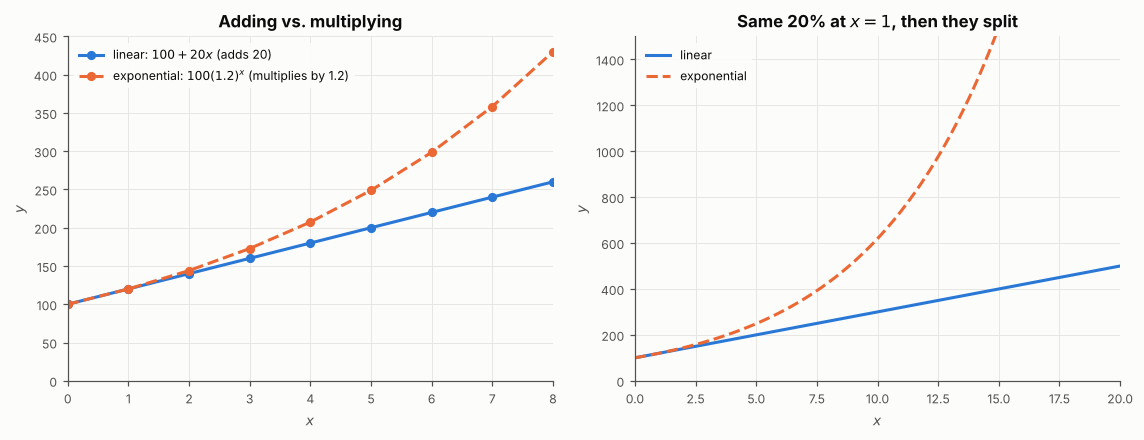

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.1))
ax = axes[0]; data_axes(ax, "Adding vs. multiplying", "$x$", "$y$")
x = np.arange(0, 9)
ax.plot(x, 100 + 20*x, "-o", color=BLUE, ms=5, label="linear: $100 + 20x$ (adds 20)")
ax.plot(x, 100*1.2**x, "--o", color=ORANGE, ms=5, label="exponential: $100(1.2)^x$ (multiplies by 1.2)")
ax.set_xlim(0, 8); ax.set_ylim(0, 450); ax.legend(loc="upper left", fontsize=8)

ax = axes[1]; data_axes(ax, "Same 20% at $x = 1$, then they split", "$x$", "$y$")
x = np.linspace(0, 20, 200)
ax.plot(x, 100 + 20*x, color=BLUE, label="linear")
ax.plot(x, 100*1.2**x, color=ORANGE, ls="--", label="exponential")
ax.set_xlim(0, 20); ax.set_ylim(0, 1500); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

### Compound interest and the number $e$

| Compounding | Formula |
|---|---|
| $n$ times per year | $A(t) = P\left(1 + \dfrac{r}{n}\right)^{nt}$ |
| Continuously | $A(t) = Pe^{rt}$ |

As $n$ grows, $\left(1 + \dfrac{1}{n}\right)^n$ approaches $e \approx 2.71828$, which is why continuous compounding uses $e$.

**Worked example.** \$1000 at 4% for 10 years:

$$
\text{monthly: } 1000\left(1 + \tfrac{0.04}{12}\right)^{120} \approx \$1490.83,
\qquad
\text{continuously: } 1000e^{0.4} \approx \$1491.82
$$

### Continuous growth and decay

$$
A(t) = ae^{rt}, \qquad r > 0 \text{ growth}, \quad r < 0 \text{ decay}
$$

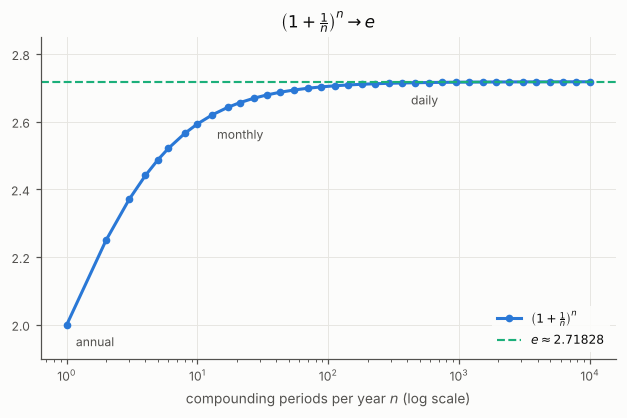

In [4]:
fig, ax = plt.subplots(figsize=(5.8, 3.9))
data_axes(ax, r"$\left(1 + \frac{1}{n}\right)^n \to e$", "compounding periods per year $n$ (log scale)", "")
n = np.unique(np.logspace(0, 4, 40).astype(int))
ax.set_xscale("log")
ax.plot(n, (1 + 1/n)**n, "o-", color=BLUE, ms=4, label=r"$\left(1 + \frac{1}{n}\right)^n$")
ax.axhline(np.e, color=AQUA, ls="--", lw=1.4, label=r"$e \approx 2.71828$")
for nn, lab in [(1, "annual"), (12, "monthly"), (365, "daily")]:
    ax.annotate(lab, (nn, (1 + 1/nn)**nn), textcoords="offset points", xytext=(6, -14), fontsize=8, color=INK2)
ax.set_ylim(1.9, 2.85); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Using $b = 0.06$ for 6% growth. The factor is $b = 1.06$.
- Reading $ab^x$ as $(ab)^x$. The exponent applies only to $b$: $2 \cdot 3^2 = 18$, not $36$.
- Subtracting the two equations instead of dividing when finding $b$ from two points.
- Mixing up $r$ (the annual rate) and $n$ (the periods per year) in the compound interest formula. The exponent is $nt$, the total number of periods.
:::

:::{important} The book underplays this
"5% annual growth" ($b = 1.05$) and "5% continuous growth" ($e^{0.05t}$) are different models. They're linked by $b = e^{k}$, so $k = \ln b$: 5% annual growth is $k = \ln 1.05 \approx 0.0488$ continuous. The book saves this conversion for §6.7, but it's the key to switching between the two forms.
:::

:::{tip} Where this shows up
Unlimited population growth in discrete time is $N_t = N_0 \lambda^t$, where $\lambda$ (the finite rate of increase) is a growth factor $b$; the continuous version is $N(t) = N_0 e^{rt}$ with $r = \ln \lambda$. Population viability analyses and matrix models (the dominant eigenvalue of a Leslie matrix is $\lambda$) all build on this.
:::

(sec-6-2)=
## 6.2 Graphs of Exponential Functions

### The parent graph $f(x) = b^x$

| Feature | Value |
|---|---|
| Domain | $(-\infty, \infty)$ |
| Range | $(0, \infty)$ |
| $y$-intercept | $(0, 1)$ |
| Horizontal asymptote | $y = 0$ |
| Shape | increasing if $b > 1$, decreasing if $0 < b < 1$ |
| Key points | $\left(-1, \dfrac{1}{b}\right),\ (0, 1),\ (1, b)$ |

$\left(\dfrac{1}{b}\right)^x = b^{-x}$, so the decay graph is the growth graph reflected across the $y$-axis.

### Transformations

$$
f(x) = a\,b^{x + c} + d
$$

The §3.5 rules apply unchanged: $c$ shifts left/right, $d$ shifts up/down **and moves the asymptote to $y = d$**, $a$ stretches or reflects. The range becomes $(d, \infty)$ if $a > 0$ and $(-\infty, d)$ if $a < 0$.

**Worked example.** $f(x) = 2^{x + 1} - 3$: shift $2^x$ left 1 and down 3.

- Asymptote $y = -3$; domain $\mathbb{R}$; range $(-3, \infty)$.
- $y$-intercept: $f(0) = 2 - 3 = -1$.
- $x$-intercept: $2^{x + 1} = 3$, so $x = \log_2 3 - 1 \approx 0.585$ (solved with logs in §6.6).

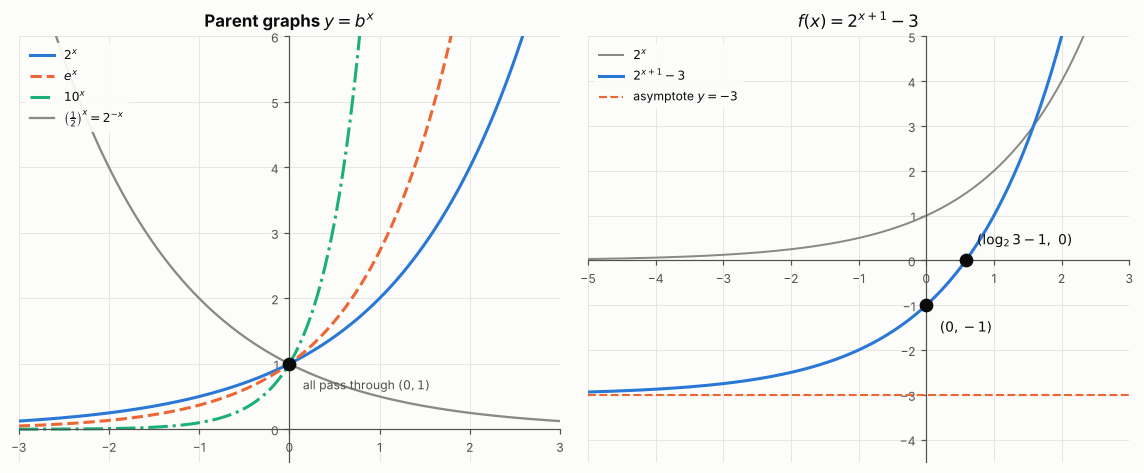

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
ax = axes[0]; setup(ax, (-3, 3), (-0.5, 6), "Parent graphs $y = b^x$"); ax.set_aspect("auto")
x = np.linspace(-3, 3, 300)
ax.plot(x, clip(2**x, 6.5), color=BLUE, label="$2^x$")
ax.plot(x, clip(np.e**x, 6.5), color=ORANGE, ls="--", label="$e^x$")
ax.plot(x, clip(10**x, 6.5), color=AQUA, ls="-.", label="$10^x$")
ax.plot(x, clip(0.5**x, 6.5), color=GRAY, lw=1.5, label=r"$\left(\frac{1}{2}\right)^x = 2^{-x}$")
dot(ax, 0, 1, color=INK); ax.text(0.15, 0.6, "all pass through $(0, 1)$", fontsize=8, color=INK2)
ax.legend(loc="upper left", fontsize=8)

ax = axes[1]; setup(ax, (-5, 3), (-4.5, 5), "$f(x) = 2^{x+1} - 3$"); ax.set_aspect("auto")
x = np.linspace(-5, 3, 300)
ax.plot(x, 2**x, color=GRAY, lw=1.3, label="$2^x$")
ax.plot(x, clip(2**(x + 1) - 3, 6), color=BLUE, label="$2^{x+1} - 3$")
ax.axhline(-3, color=ORANGE, ls="--", lw=1.4, label="asymptote $y = -3$")
dot(ax, 0, -1, color=INK); dot(ax, np.log2(3) - 1, 0, color=INK)
ax.text(0.2, -1.6, "$(0, -1)$", fontsize=9); ax.text(0.75, 0.35, r"$(\log_2 3 - 1,\ 0)$", fontsize=9)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Leaving the asymptote at $y = 0$ after a vertical shift. The asymptote moves with $d$.
- Writing the range as $(0, \infty)$ for a shifted or reflected exponential.
- Thinking an exponential can reach its asymptote. $b^x > 0$ for every $x$.
- Shifting the wrong way: $2^{x + 1}$ moves **left** 1, just as in §3.5.
:::

:::{tip} Where this shows up
The exponential distribution's density, $\lambda e^{-\lambda x}$, is a decaying exponential and is the waiting-time model for Poisson events. The normal density $e^{-x^2/2}$ is an exponential whose exponent is a downward parabola; that's why the bell curve has asymptote $y = 0$ in both tails.
:::

(sec-6-3)=
## 6.3 Logarithmic Functions

### Definition

The logarithm is the exponent:

$$
y = \log_b x \iff b^y = x, \qquad b > 0,\ b \ne 1,\ x > 0.
$$

"$\log_b x$" answers: *to what power must I raise $b$ to get $x$?*

| Name | Notation | Base |
|---|---|---|
| Common log | $\log x$ | $10$ |
| Natural log | $\ln x$ | $e$ |

### Converting between forms

| Exponential form | Logarithmic form |
|---|---|
| $3^4 = 81$ | $\log_3 81 = 4$ |
| $10^{-2} = 0.01$ | $\log 0.01 = -2$ |
| $e^{0.5} = \sqrt{e}$ | $\ln \sqrt{e} = \tfrac{1}{2}$ |

The base of the exponential is the base of the log, and the exponent is what the log equals.

### Evaluating without a calculator

Rewrite the argument as a power of the base:

$$
\log_2 32 = 5 \ (2^5 = 32), \qquad
\log_3 \tfrac{1}{9} = -2 \ (3^{-2} = \tfrac{1}{9}), \qquad
\log_4 2 = \tfrac{1}{2} \ (4^{1/2} = 2), \qquad
\ln 1 = 0
$$

### Inverse identities

$$
\log_b\left(b^x\right) = x \ \text{ for all } x, \qquad b^{\log_b x} = x \ \text{ for } x > 0.
$$

**Worked example.** Solve $10^x = 500$: $x = \log 500 \approx 2.699$.

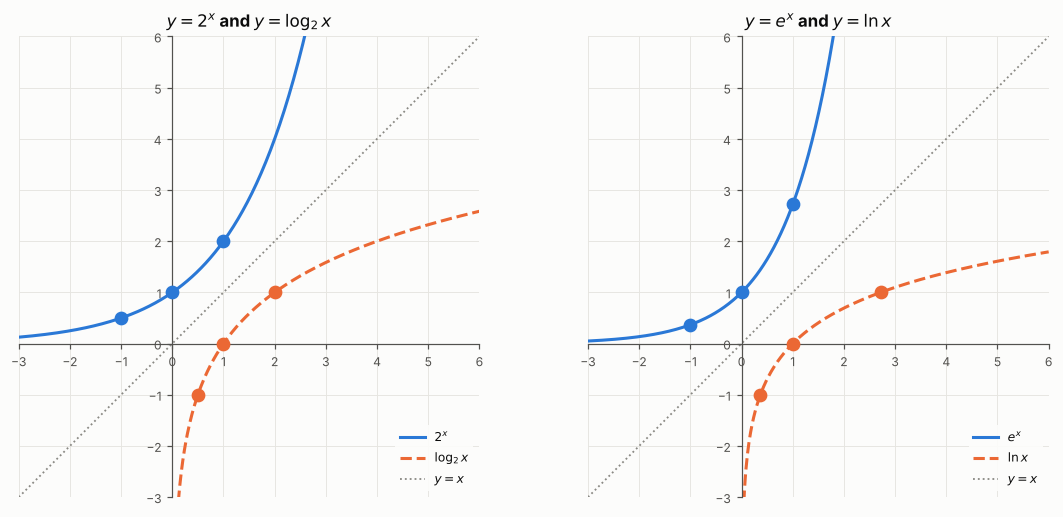

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8))
for ax, b, name in [(axes[0], 2, "2"), (axes[1], np.e, "e")]:
    setup(ax, (-3, 6), (-3, 6), f"$y = {name}^x$ and $y = \\log_{{{name}}} x$" if name == "2"
          else "$y = e^x$ and $y = \\ln x$")
    x = np.linspace(-3, 6, 400)
    ax.plot(x, clip(b**x, 6.5), color=BLUE, label=f"${name}^x$")
    xp = np.linspace(0.01, 6, 400)
    ax.plot(xp, np.log(xp)/np.log(b), color=ORANGE, ls="--", label=f"$\\log_{{{name}}} x$" if name == "2" else r"$\ln x$")
    ax.plot([-3, 6], [-3, 6], color=GRAY, ls=":", lw=1.2, label="$y = x$")
    for (px, py) in [(-1, 1/b), (0, 1), (1, b)]:
        dot(ax, px, py, color=BLUE); dot(ax, py, px, color=ORANGE)
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Writing $\log_3 81 = 4$ as $4^3 = 81$. The base stays the base: $3^4 = 81$.
- Taking the log of $0$ or a negative number. $\log_b x$ is defined only for $x > 0$, because $b^y$ is always positive.
- Treating $\log_b x$ as $\log_b$ times $x$. It's a function evaluated at $x$.
- Thinking a log can't be negative. Arguments between $0$ and $1$ give negative logs: $\log 0.01 = -2$.
:::

:::{important} The book underplays this
In statistics, calculus, and code, "log" almost always means the **natural** log. Python's `np.log`, R's `log`, and every log-likelihood use base $e$; base 10 needs `np.log10`. Stewart uses $\ln$ throughout because $\dfrac{d}{dx}\ln x = \dfrac{1}{x}$ has no extra constant.
:::

:::{tip} Where this shows up
Log-likelihoods, log-odds ($\ln \tfrac{p}{1 - p}$), and log-transformed counts all use $\ln$. Shannon diversity, $H = -\sum p_i \ln p_i$, is a sum of logs. pH and the Richter scale are base-10 logs, which is why one unit is a tenfold change.
:::

(sec-6-4)=
## 6.4 Graphs of Logarithmic Functions

### The parent graph $f(x) = \log_b x$

Swap the coordinates of $b^x$ (§6.2):

| Feature | Value |
|---|---|
| Domain | $(0, \infty)$ |
| Range | $(-\infty, \infty)$ |
| $x$-intercept | $(1, 0)$ |
| Vertical asymptote | $x = 0$ |
| Key points | $\left(\dfrac{1}{b}, -1\right),\ (1, 0),\ (b, 1)$ |

### Domain of a log

Set the argument **strictly greater than 0** and solve.

**Worked example.** $f(x) = \log(5 - 2x)$: $5 - 2x > 0 \implies x < \tfrac{5}{2}$. Domain $\left(-\infty, \tfrac{5}{2}\right)$; vertical asymptote $x = \tfrac{5}{2}$.

### Transformations

$$
f(x) = a\log_b(x + c) + d
$$

The vertical asymptote is where the argument is $0$: $x = -c$. A vertical shift $d$ does **not** move the asymptote (unlike the exponential case, where $d$ does).

**Worked example.** $f(x) = -2\ln(x - 3) + 1$.

$$
\begin{aligned}
\text{Domain: } & x - 3 > 0 \implies (3, \infty); \quad \text{asymptote } x = 3 \\
x\text{-intercept: } & -2\ln(x - 3) + 1 = 0 \implies \ln(x - 3) = \tfrac{1}{2} \implies x = 3 + e^{1/2} \approx 4.649 \\
\text{Shape: } & \ln x \text{ shifted right 3, stretched by 2, reflected over the } x\text{-axis, shifted up 1}
\end{aligned}
$$

There is no $y$-intercept, since $x = 0$ is not in the domain.

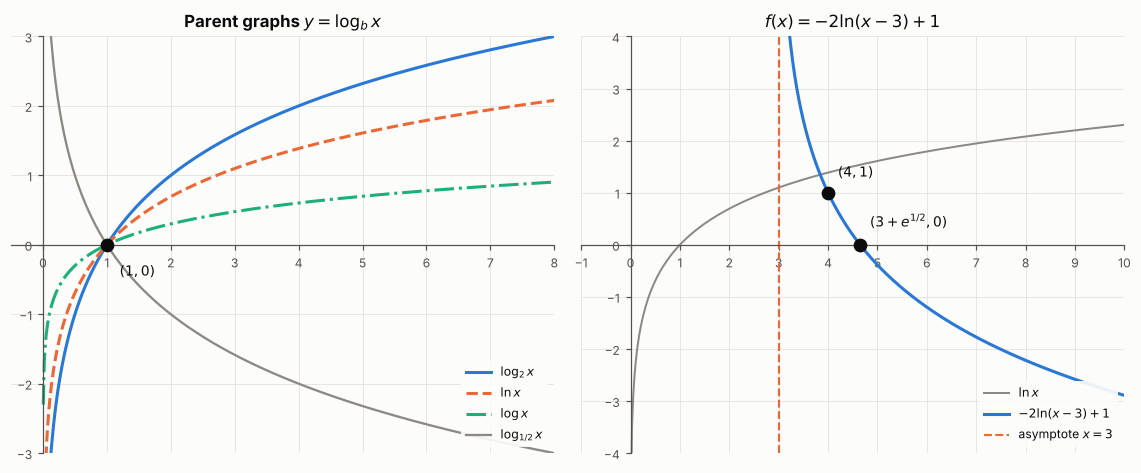

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
ax = axes[0]; setup(ax, (-0.5, 8), (-3, 3), "Parent graphs $y = \\log_b x$"); ax.set_aspect("auto")
x = np.linspace(0.005, 8, 500)
ax.plot(x, np.log2(x), color=BLUE, label=r"$\log_2 x$")
ax.plot(x, np.log(x), color=ORANGE, ls="--", label=r"$\ln x$")
ax.plot(x, np.log10(x), color=AQUA, ls="-.", label=r"$\log x$")
ax.plot(x, -np.log2(x), color=GRAY, lw=1.5, label=r"$\log_{1/2} x$")
dot(ax, 1, 0, color=INK); ax.text(1.2, -0.45, "$(1, 0)$", fontsize=9)
ax.legend(loc="lower right", fontsize=8)

ax = axes[1]; setup(ax, (-1, 10), (-4, 4), r"$f(x) = -2\ln(x - 3) + 1$"); ax.set_aspect("auto")
x = np.linspace(3.002, 10, 500)
ax.plot(np.linspace(0.005, 10, 400), np.log(np.linspace(0.005, 10, 400)), color=GRAY, lw=1.3, label=r"$\ln x$")
ax.plot(x, clip(-2*np.log(x - 3) + 1, 4.5), color=BLUE, label=r"$-2\ln(x - 3) + 1$")
ax.axvline(3, color=ORANGE, ls="--", lw=1.4, label="asymptote $x = 3$")
xi = 3 + np.exp(0.5); dot(ax, xi, 0, color=INK); ax.text(xi + 0.2, 0.35, "$(3 + e^{1/2}, 0)$", fontsize=9)
dot(ax, 4, 1, color=INK); ax.text(4.2, 1.3, "$(4, 1)$", fontsize=9)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Using $\ge 0$ for the domain. The argument must be **strictly** positive.
- Putting the vertical asymptote at $x = 0$ after a horizontal shift. It's where the argument equals $0$.
- Moving the asymptote for a vertical shift. $\log(x) + 5$ still has asymptote $x = 0$.
- Giving a $y$-intercept when $0$ isn't in the domain.
:::

:::{tip} Where this shows up
Log transforms only work on positive data, which is why zero counts force choices like $\log(y + 1)$ or, better, a model with a log link (Poisson or negative binomial GLM) that never logs the data. Diminishing returns (each doubling of effort adds the same amount) is a log curve: species accumulation with sampling effort often looks like this.
:::

(sec-6-5)=
## 6.5 Logarithmic Properties

Each rule is an exponent rule (§1.2) read in reverse. For $b > 0$, $b \ne 1$, and positive $M, N$:

| Rule | Logarithm form | Exponent rule behind it |
|---|---|---|
| Product | $\log_b(MN) = \log_b M + \log_b N$ | $b^m b^n = b^{m + n}$ |
| Quotient | $\log_b\left(\dfrac{M}{N}\right) = \log_b M - \log_b N$ | $\dfrac{b^m}{b^n} = b^{m - n}$ |
| Power | $\log_b\left(M^p\right) = p\log_b M$ | $(b^m)^p = b^{mp}$ |
| Change of base | $\log_b M = \dfrac{\ln M}{\ln b} = \dfrac{\log M}{\log b}$ | |
| Special values | $\log_b 1 = 0$, $\log_b b = 1$ | $b^0 = 1$, $b^1 = b$ |

**Worked example (expand).** Write radicals as powers first.

$$
\begin{aligned}
\ln\left(\frac{x^3\sqrt{y}}{z^2(x + 1)}\right)
&= \ln\left(x^3 y^{1/2}\right) - \ln\left(z^2(x + 1)\right) \\
&= 3\ln x + \tfrac{1}{2}\ln y - 2\ln z - \ln(x + 1)
\end{aligned}
$$

$\ln(x + 1)$ stops there: there's no rule for the log of a sum.

**Worked example (condense).** Coefficients become powers first, then combine:

$$
2\log x - 3\log y + \tfrac{1}{2}\log z = \log x^2 - \log y^3 + \log \sqrt{z} = \log\left(\frac{x^2\sqrt{z}}{y^3}\right)
$$

**Worked example (change of base).** $\log_5 100 = \dfrac{\ln 100}{\ln 5} \approx \dfrac{4.605}{1.609} \approx 2.861$. Check: $5^{2.861} \approx 100$.

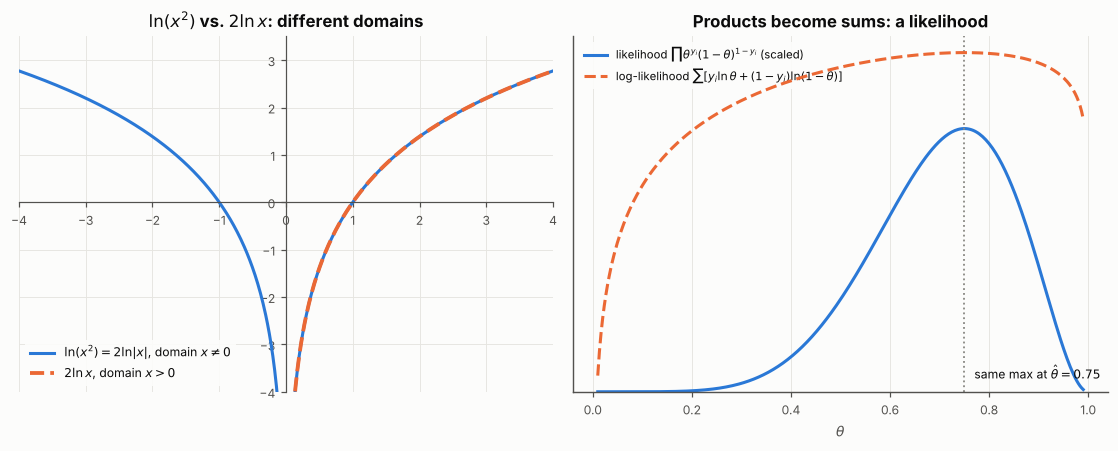

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
ax = axes[0]; setup(ax, (-4, 4), (-4, 3.5), r"$\ln(x^2)$ vs. $2\ln x$: different domains"); ax.set_aspect("auto")
xp = np.linspace(0.01, 4, 300); xn = np.linspace(-4, -0.01, 300)
ax.plot(xn, np.log(xn**2), color=BLUE, label=r"$\ln(x^2) = 2\ln|x|$, domain $x \neq 0$")
ax.plot(xp, np.log(xp**2), color=BLUE)
ax.plot(xp, 2*np.log(xp), color=ORANGE, ls="--", lw=2.5, label=r"$2\ln x$, domain $x > 0$")
ax.legend(loc="lower left", fontsize=8)

ax = axes[1]; data_axes(ax, "Products become sums: a likelihood", r"$\theta$", "")
th = np.linspace(0.01, 0.99, 300); y = np.array([1, 0, 1, 1, 0, 1, 1, 1])
L = np.prod([th**yi*(1 - th)**(1 - yi) for yi in y], axis=0)
ax.plot(th, L/L.max(), color=BLUE, label=r"likelihood $\prod \theta^{y_i}(1-\theta)^{1-y_i}$ (scaled)")
ax2 = ax.twinx(); ax2.set_yticks([])
for s in ("right", "top"): ax2.spines[s].set_visible(False)
ax.plot([], [], color=ORANGE, ls="--", label=r"log-likelihood $\sum [y_i\ln\theta + (1-y_i)\ln(1-\theta)]$")
ax2.plot(th, np.sum([yi*np.log(th) + (1 - yi)*np.log(1 - th) for yi in y], axis=0), color=ORANGE, ls="--")
ax.axvline(y.mean(), color=GRAY, ls=":", lw=1.2); ax.text(y.mean() + 0.02, 0.05, r"same max at $\hat\theta = 0.75$", fontsize=8)
ax.legend(loc="upper left", fontsize=7.5); ax.set_ylim(0, 1.35); ax.set_yticks([])
plt.tight_layout(); plt.show()

The right panel uses only one fact from this section: the log of a product is a sum of logs. Because $\ln$ is increasing, the likelihood and the log-likelihood peak at the same $\theta$. The vertical scale differs between the two curves, so only the location of the peak is comparable.

:::{admonition} Common mistakes
:class: warning
- $\log(M + N) \ne \log M + \log N$. The product rule is for the log of a **product**.
- $\dfrac{\log M}{\log N} \ne \log\left(\dfrac{M}{N}\right)$. A quotient **of logs** is a change of base, not the quotient rule.
- $(\log x)^2 \ne 2\log x$. The power rule needs the power **inside**: $\log(x^2) = 2\log x$.
- Condensing before turning coefficients into powers: $2\log x + \log y = \log(x^2 y)$, not $\log(2xy)$.
:::

:::{important} The book underplays this
The power rule can change the domain. $\ln(x^2)$ is defined for every $x \ne 0$, but $2\ln x$ only for $x > 0$; the correct identity is $\ln(x^2) = 2\ln\lvert x \rvert$. The left panel shows the half of the graph that "$2\ln x$" silently drops. This matters when solving equations in §6.6.
:::

:::{tip} Where this shows up
This section is the reason log-likelihoods exist. A likelihood is a product of $n$ terms; its log is a sum, which is easier to differentiate (Casella & Berger) and doesn't underflow to zero on a computer. Change of base is why "bits" ($\log_2$) and "nats" ($\ln$) of information differ only by the constant $\ln 2$.
:::

(sec-6-6)=
## 6.6 Exponential and Logarithmic Equations

### Strategy

| Equation looks like | Method |
|---|---|
| Both sides are powers of the same base | Set the exponents equal: $b^S = b^T \implies S = T$ |
| Different bases | Take $\ln$ of both sides; use the power rule to bring exponents down |
| $e^{\text{something}}$ isolated | Take $\ln$: $e^S = c \implies S = \ln c$ (for $c > 0$) |
| Quadratic in $e^x$ or $b^x$ | Substitute $u = e^x$, solve for $u$, then $x = \ln u$ |
| A single log $= c$ | Rewrite in exponential form: $\log_b S = c \implies S = b^c$ |
| Log $=$ log, same base | One-to-one: $\log_b S = \log_b T \implies S = T$ |
| Several logs | Condense to one log first (§6.5) |

**Always check** answers from log equations in the original: any value that makes an argument $\le 0$ is extraneous.

**Worked example (common base).** $4^{x + 1} = 8^x \implies 2^{2x + 2} = 2^{3x} \implies 2x + 2 = 3x \implies x = 2$.

**Worked example (different bases).**

$$
\begin{aligned}
5^x &= 3^{x + 2} \\
x\ln 5 &= (x + 2)\ln 3 \\
x\ln 5 - x\ln 3 &= 2\ln 3 \\
x &= \frac{2\ln 3}{\ln 5 - \ln 3} \approx 4.301
\end{aligned}
$$

**Worked example (quadratic form).** $e^{2x} - e^x - 6 = 0$. With $u = e^x$: $u^2 - u - 6 = (u - 3)(u + 2) = 0$. $e^x = 3$ gives $x = \ln 3$; $e^x = -2$ has no solution.

**Worked example (log equation, extraneous root).**

$$
\begin{aligned}
\log_2 x + \log_2(x - 2) &= 3 \\
\log_2\big(x(x - 2)\big) &= 3 \\
x^2 - 2x &= 8 \implies (x - 4)(x + 2) = 0
\end{aligned}
$$

$x = 4$ works. $x = -2$ makes $\log_2(-2)$ undefined, so it's extraneous.

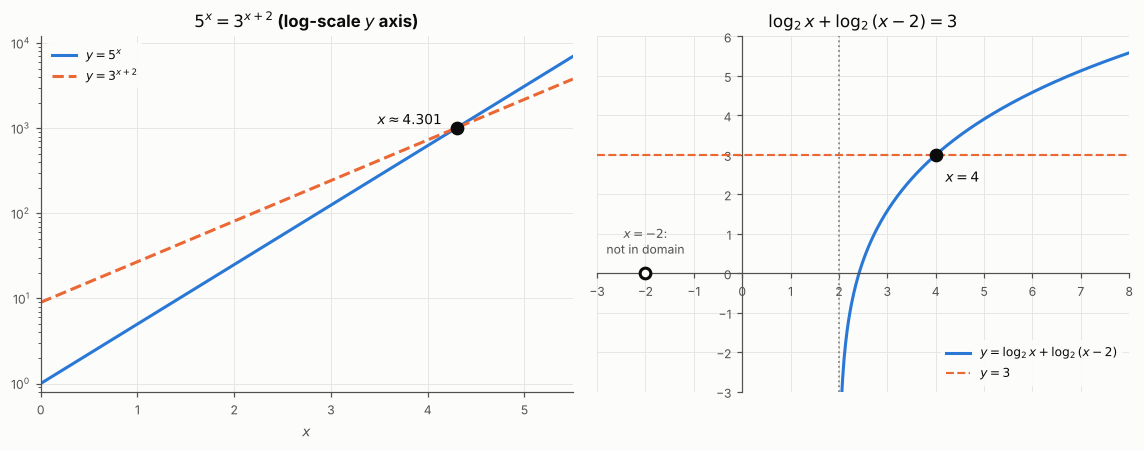

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
ax = axes[0]; data_axes(ax, "$5^x = 3^{x+2}$ (log-scale $y$ axis)", "$x$", ""); ax.set_yscale("log")
x = np.linspace(0, 5.5, 300)
ax.plot(x, 5**x, color=BLUE, label="$y = 5^x$"); ax.plot(x, 3**(x + 2), color=ORANGE, ls="--", label="$y = 3^{x+2}$")
xs = 2*np.log(3)/(np.log(5) - np.log(3)); dot(ax, xs, 5**xs, color=INK)
ax.text(xs - 0.15, 5**xs*1.08, f"$x \\approx {xs:.3f}$", ha="right", fontsize=9)
ax.set_xlim(0, 5.5); ax.set_ylim(0.8, 12000); ax.legend(loc="upper left", fontsize=8)

ax = axes[1]; setup(ax, (-3, 8), (-3, 6), r"$\log_2 x + \log_2(x - 2) = 3$"); ax.set_aspect("auto")
x = np.linspace(2.001, 8, 400)
ax.plot(x, np.log2(x) + np.log2(x - 2), color=BLUE, label=r"$y = \log_2 x + \log_2(x - 2)$")
ax.axhline(3, color=ORANGE, ls="--", lw=1.4, label="$y = 3$")
ax.axvline(2, color=GRAY, ls=":", lw=1.2)
dot(ax, 4, 3, color=INK); ax.text(4.2, 2.3, "$x = 4$", fontsize=9)
dot(ax, -2, 0, filled=False, color=INK); ax.text(-2, 0.5, "$x = -2$:\nnot in domain", ha="center", fontsize=8, color=INK2)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Taking the log of a sum term by term: from $e^x + 2 = 7$, isolate first ($e^x = 5$), then take $\ln$.
- Cancelling $\ln$ across a sum: $\ln x + \ln 3 = \ln 12$ condenses to $\ln(3x) = \ln 12$, not $x + 3 = 12$.
- Dividing $\dfrac{\ln 3}{\ln 5}$ into $\ln\tfrac{3}{5}$. Leave it as a quotient, or compute it.
- Skipping the check for log equations. Extraneous roots are common.
- Keeping a solution of $e^x = -2$. Exponentials are never negative.
:::

:::{tip} Where this shows up
"How long until the population reaches 500?" is solving $N_0e^{rt} = 500$ for $t$: $t = \dfrac{1}{r}\ln\dfrac{500}{N_0}$. Setting a derivative of a log-likelihood to zero and solving is the same skill one step later, in Casella & Berger.
:::

(sec-6-7)=
## 6.7 Exponential and Logarithmic Models

### Growth and decay

$$
A(t) = A_0 e^{kt}, \qquad k > 0 \text{ growth}, \quad k < 0 \text{ decay}
$$

| Quantity | Formula |
|---|---|
| Doubling time ($k > 0$) | $T_2 = \dfrac{\ln 2}{k}$ |
| Half-life ($k < 0$) | $T_{1/2} = \dfrac{\ln 2}{\lvert k \rvert}$, so $k = -\dfrac{\ln 2}{T_{1/2}}$ |
| Half-life form | $A(t) = A_0\left(\tfrac{1}{2}\right)^{t / T_{1/2}}$ |
| Converting $ab^t$ to base $e$ | $ab^t = ae^{(\ln b)t}$ |

**Worked example (half-life).** Cesium-137 has a half-life of about 30 years. The fraction left after 100 years is $\left(\tfrac{1}{2}\right)^{100/30} \approx 0.099$, about 10%. In base-$e$ form, $k = -\dfrac{\ln 2}{30} \approx -0.0231$.

**Worked example (doubling).** A population growing at a continuous 3% per year doubles every $\dfrac{\ln 2}{0.03} \approx 23.1$ years.

### Newton's Law of Cooling

$$
T(t) = Ae^{kt} + T_s
$$

where $T_s$ is the surrounding temperature and $A = T(0) - T_s$. The **difference** from the surroundings decays exponentially.

**Worked example.** Soup at 180°F in a 70°F room is 150°F after 5 minutes. When does it reach 100°F?

$$
\begin{aligned}
T(t) &= 110e^{kt} + 70 \\
150 = 110e^{5k} + 70 &\implies e^{5k} = \tfrac{80}{110} \implies k = \tfrac{1}{5}\ln\tfrac{8}{11} \approx -0.0637 \\
100 = 110e^{kt} + 70 &\implies t = \frac{\ln(30/110)}{k} \approx 20.4 \text{ minutes}
\end{aligned}
$$

### Logistic growth

$$
f(t) = \frac{c}{1 + ae^{-bt}}
$$

- $c$ is the **carrying capacity** (horizontal asymptote). The initial value is $f(0) = \dfrac{c}{1 + a}$.
- Growth is fastest at the **inflection point**, where $f = \dfrac{c}{2}$, at $t = \dfrac{\ln a}{b}$.

**Worked example.** A stocked fish population follows $P(t) = \dfrac{1000}{1 + 9e^{-0.6t}}$ ($t$ in years). Then $P(0) = 100$, the carrying capacity is 1000, and growth is fastest when $P = 500$, at $t = \dfrac{\ln 9}{0.6} \approx 3.66$ years.

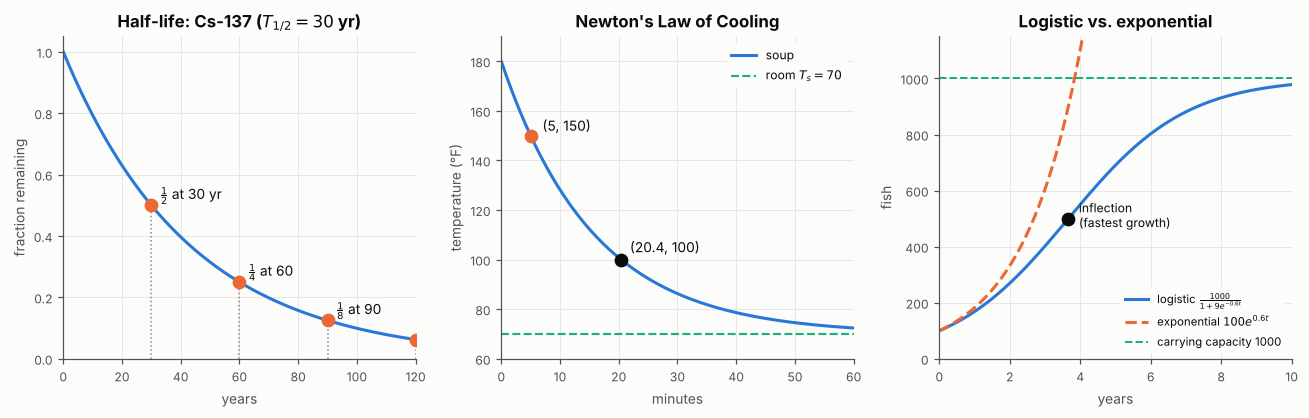

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
ax = axes[0]; data_axes(ax, "Half-life: Cs-137 ($T_{1/2} = 30$ yr)", "years", "fraction remaining")
t = np.linspace(0, 120, 300); ax.plot(t, 0.5**(t/30), color=BLUE)
for k in range(1, 5):
    ax.plot([30*k, 30*k], [0, 0.5**k], color=GRAY, ls=":", lw=1); dot(ax, 30*k, 0.5**k, color=ORANGE)
ax.text(33, 0.52, r"$\frac{1}{2}$ at 30 yr", fontsize=9); ax.text(63, 0.27, r"$\frac{1}{4}$ at 60", fontsize=9)
ax.text(93, 0.145, r"$\frac{1}{8}$ at 90", fontsize=9)
ax.set_xlim(0, 120); ax.set_ylim(0, 1.05)

ax = axes[1]; data_axes(ax, "Newton's Law of Cooling", "minutes", "temperature (°F)")
k = np.log(8/11)/5; t = np.linspace(0, 60, 300)
ax.plot(t, 110*np.exp(k*t) + 70, color=BLUE, label="soup")
ax.axhline(70, color=AQUA, ls="--", lw=1.4, label="room $T_s = 70$")
t100 = np.log(30/110)/k; dot(ax, 5, 150, color=ORANGE); dot(ax, t100, 100, color=INK)
ax.text(7, 152, "(5, 150)", fontsize=9); ax.text(t100 + 1.5, 103, f"({t100:.1f}, 100)", fontsize=9)
ax.set_xlim(0, 60); ax.set_ylim(60, 190); ax.legend(loc="upper right", fontsize=8)

ax = axes[2]; data_axes(ax, "Logistic vs. exponential", "years", "fish")
t = np.linspace(0, 10, 300)
ax.plot(t, 1000/(1 + 9*np.exp(-0.6*t)), color=BLUE, label=r"logistic $\frac{1000}{1 + 9e^{-0.6t}}$")
ax.plot(t, clip(100*np.exp(0.6*t), 1200), color=ORANGE, ls="--", label=r"exponential $100e^{0.6t}$")
ax.axhline(1000, color=AQUA, ls="--", lw=1.3, label="carrying capacity 1000")
ti = np.log(9)/0.6; dot(ax, ti, 500, color=INK); ax.text(ti + 0.3, 470, "inflection\n(fastest growth)", fontsize=8)
ax.set_xlim(0, 10); ax.set_ylim(0, 1150); ax.legend(loc="lower right", fontsize=7.5)
plt.tight_layout(); plt.show()

### Choosing a model

| Pattern in the data | Model |
|---|---|
| Constant differences | linear |
| Constant ratios; rising faster and faster (or decaying toward 0) | exponential |
| Rising quickly, then slowing without a ceiling | logarithmic |
| S-shape that levels off at a ceiling | logistic |

:::{admonition} Common mistakes
:class: warning
- Using the half-life as $k$. Convert: $k = -\dfrac{\ln 2}{T_{1/2}}$.
- In Newton's Law, setting $A$ to the starting temperature. $A$ is the starting **difference**, $T(0) - T_s$.
- Forgetting the negative sign in the logistic exponent, which would make the curve decrease.
- Rounding $k$ early. Keep it exact (as $\tfrac{1}{5}\ln\tfrac{8}{11}$) or to many digits until the last step.
:::

:::{important} The book underplays this
The logistic curve grows fastest at **half the carrying capacity**. In fisheries, that's the logic of maximum sustainable yield: harvesting holds a stock near $K/2$, where it regrows fastest. The logistic function is also the inverse logit, $\dfrac{1}{1 + e^{-x}}$, used to turn a linear predictor into a probability in logistic regression and occupancy models.
:::

:::{tip} Where this shows up
The logistic curve solves the differential equation $\dfrac{dN}{dt} = rN\left(1 - \dfrac{N}{K}\right)$, a staple of population ecology and a Stewart example. Newton's Law has the same form as the von Bertalanffy growth curve, $L(t) = L_\infty\left(1 - e^{-k(t - t_0)}\right)$, used for fish length-at-age.
:::

(sec-6-8)=
## 6.8 Fitting Exponential Models to Data

The book fits three nonlinear models with calculator commands:

| Calculator command | Model | Use when |
|---|---|---|
| ExpReg | $y = ab^x$ | steady percentage growth or decay |
| LnReg | $y = a + b\ln x$ | fast early change that keeps slowing |
| Logistic | $y = \dfrac{c}{1 + ae^{-bx}}$ | S-shape with a ceiling |

### Linearizing an exponential model

Taking $\ln$ of $y = ab^x$ gives

$$
\ln y = \ln a + (\ln b)\,x,
$$

a straight line in $x$ and $\ln y$. So: plot $\ln y$ against $x$. If it looks linear, fit a line with §4.3 least squares, then back-transform: $a = e^{\text{intercept}}$, $b = e^{\text{slope}}$.

**Worked example.**

| $x$ | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| $y$ | 3.1 | 4.4 | 6.9 | 10.2 | 15.4 |
| $\ln y$ | 1.131 | 1.482 | 1.932 | 2.322 | 2.734 |

The ratios $y_{i+1}/y_i$ are all near 1.5, which points to exponential. Least squares on $(x, \ln y)$ gives intercept $\approx 1.111$ and slope $\approx 0.405$, so

$$
a = e^{1.111} \approx 3.04, \qquad b = e^{0.405} \approx 1.50, \qquad y \approx 3.04(1.50)^x.
$$

In Python: `slope, intercept = np.polyfit(x, np.log(y), 1)`. For the logistic, use `scipy.optimize.curve_fit`.

intercept = 1.111, slope = 0.405  ->  y = 3.04 * 1.50^x


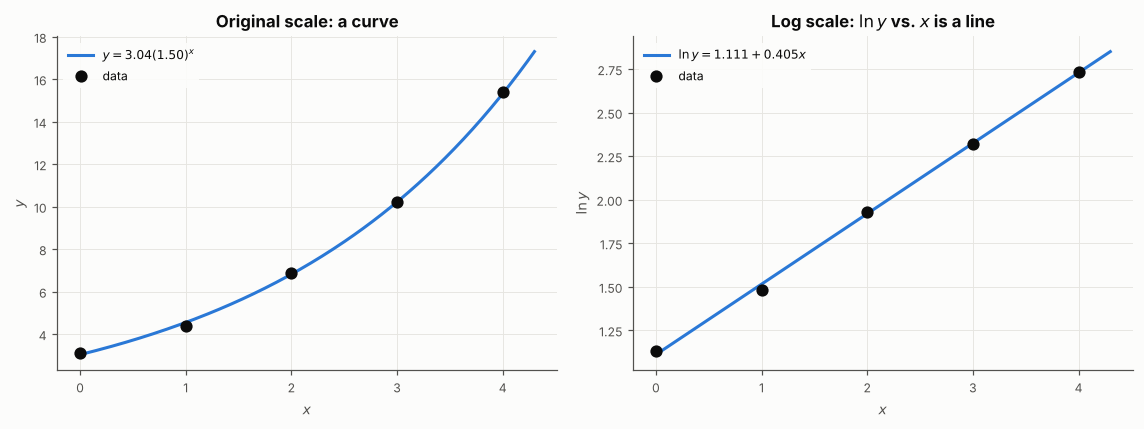

In [11]:
x = np.arange(5); y = np.array([3.1, 4.4, 6.9, 10.2, 15.4])
slope, intercept = np.polyfit(x, np.log(y), 1)
a, b = np.exp(intercept), np.exp(slope)
print(f"intercept = {intercept:.3f}, slope = {slope:.3f}  ->  y = {a:.2f} * {b:.2f}^x")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0))
xx = np.linspace(0, 4.3, 200)
ax = axes[0]; data_axes(ax, "Original scale: a curve", "$x$", "$y$")
ax.plot(xx, a*b**xx, color=BLUE, label=f"$y = {a:.2f}({b:.2f})^x$"); ax.plot(x, y, "o", color=INK, ms=7, label="data")
ax.legend(loc="upper left", fontsize=8)
ax = axes[1]; data_axes(ax, r"Log scale: $\ln y$ vs. $x$ is a line", "$x$", r"$\ln y$")
ax.plot(xx, intercept + slope*xx, color=BLUE, label=f"$\\ln y = {intercept:.3f} + {slope:.3f}x$")
ax.plot(x, np.log(y), "o", color=INK, ms=7, label="data")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

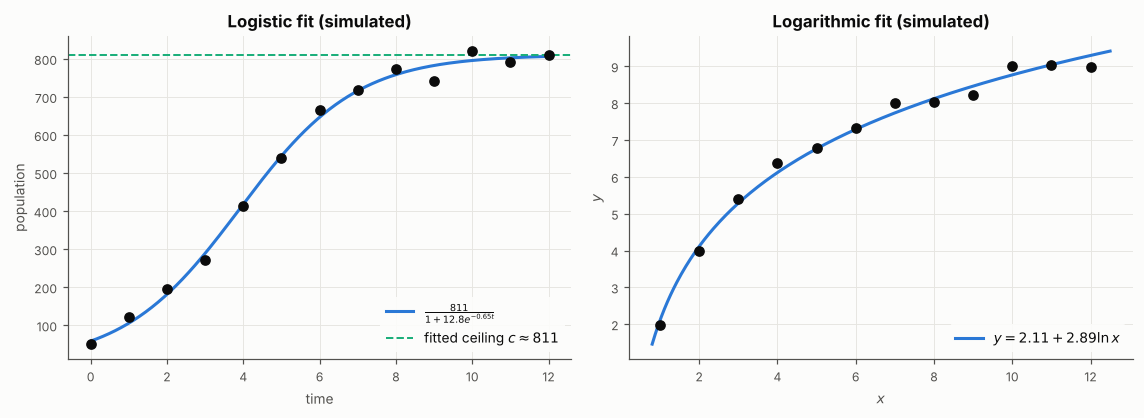

In [12]:
from scipy.optimize import curve_fit
rng = np.random.default_rng(11)
t = np.arange(0, 13)
pop = 800/(1 + 15*np.exp(-0.7*t)) + rng.normal(0, 20, t.size)       # simulated counts
logistic = lambda t, c, a, b: c/(1 + a*np.exp(-b*t))
(c, a_, b_), _ = curve_fit(logistic, t, pop, p0=[max(pop), 10, 0.5])
lx = np.linspace(1, 12, 12); ly = 2 + 3*np.log(lx) + rng.normal(0, 0.25, lx.size)
bl, al = np.polyfit(np.log(lx), ly, 1)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
ax = axes[0]; data_axes(ax, "Logistic fit (simulated)", "time", "population")
tt = np.linspace(0, 12, 300)
ax.plot(tt, logistic(tt, c, a_, b_), color=BLUE, label=f"$\\frac{{{c:.0f}}}{{1 + {a_:.1f}e^{{-{b_:.2f}t}}}}$")
ax.axhline(c, color=AQUA, ls="--", lw=1.3, label=f"fitted ceiling $c \\approx {c:.0f}$")
ax.plot(t, pop, "o", color=INK, ms=6); ax.legend(loc="lower right", fontsize=9)
ax = axes[1]; data_axes(ax, "Logarithmic fit (simulated)", "$x$", "$y$")
xx = np.linspace(0.8, 12.5, 300)
ax.plot(xx, al + bl*np.log(xx), color=BLUE, label=f"$y = {al:.2f} + {bl:.2f}\\ln x$")
ax.plot(lx, ly, "o", color=INK, ms=6); ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Fitting an exponential to data that level off. If the ratios shrink toward 1, consider logistic.
- Forgetting to back-transform. The slope of the $\ln y$ line is $\ln b$, not $b$.
- Linearizing data with zeros or negatives. $\ln 0$ is undefined.
- Extrapolating an exponential fit. It grows without bound; real populations don't.
:::

:::{important} The book underplays this
The book treats ExpReg as a black box. Most calculators fit it exactly as above: least squares on $\ln y$. That minimizes errors on the **log** scale, which treats errors as multiplicative (a percentage of $y$). A direct nonlinear fit of $ab^x$ treats errors as additive and can give noticeably different $a$ and $b$. Which is right depends on how the data vary, and choosing between them is a modeling decision you'll make constantly in regression.
:::

:::{tip} Where this shows up
A Poisson GLM with a log link models $\ln E[Y] = \beta_0 + \beta_1 x$, the same structure as $\ln y = \ln a + (\ln b)x$ but fit without logging the data. Back-transforming a mean from the log scale introduces bias (Jensen's inequality), a classic issue with log-transformed regressions. The logistic fit here is the same curve as a logistic growth model in population ecology.
:::

## Exercises to prioritize

Odd numbers have answers in the back. §6.5 and §6.6 matter most for everything after this chapter.

| Section | Core set | Notes |
|---|---|---|
| 6.1 | Algebraic 5–43 odd; Numeric 45–49 odd; Real-World 61–67 odd | Focus on 17–21 (models from two points) and 23–37 (compound and continuous growth). |
| 6.2 | Algebraic 3–7; Graphical 9–41 odd; Numeric 43, 45 | |
| 6.3 | Algebraic 7–39 odd; Numeric 43–53 (all) | The no-calculator evaluations (43–53) build the fluency you need. |
| 6.4 | Algebraic 7–25 odd; Graphical 27–49 odd | |
| 6.5 | Algebraic 3–28 (all); Numeric 31–35 odd; Extensions 37–41 odd | Do every algebraic problem. Expanding and condensing logs is used constantly in statistics. |
| 6.6 | Algebraic 5–49 odd; Graphical 51–63 odd; Extensions 79–81 | Check every log-equation answer in the original. |
| 6.7 | Numeric 7–11 odd; Extensions 23–27 odd; Real-World 29–53 odd | Real-World is the core here. |
| 6.8 | Verbal 1–5; Graphical 7–11 odd; Numeric 11–15 odd; Technology 26–30, 36–40, 46–50 | Do the Technology problems in Python: one exponential, one logarithmic, one logistic fit. |

**Cold diagnostic.** A few days after the section work, do the **Practice Test** (1–36), timed and with no notes. The **Review Exercises** (1–67, grouped by section) are the follow-up.